## 导入库
* matplotlib。这是一个实用的绘图库，我们用它来绘制折线图。
* numpy。numpy 是处理 Python 数值数据的实用库。
* sklearn。这是 Scikit-learn 库。

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn import datasets, linear_model, model_selection

## 糖尿病数据集
1. 添加一些打印命令，显示数据矩阵的形状及其第一个元素：
> ✅ 思考一下数据与回归目标之间的关系。线性回归预测特征 X 与目标变量 y 之间的关系。你能在文档中找到糖尿病数据集的目标吗？考虑该目标，数据集展示了什么？
>> 糖尿病数据集，特征是10个和身体指标有关的数据，目标变量是一年后疾病进展的定量指标
2. 接下来，选取数据集的一个部分绘图，选择第 3 列数据。你可以使用冒号操作符选取所有行，然后用索引（2）选取第 3 列。你也可以使用 reshape(n_rows, n_columns) 重塑为二维数组，以满足绘图需求。如果某个维度设为 -1，则自动计算该维度大小。
> ✅ 随时打印数据检查其形状。
3. 现在数据准备好绘图了，可以看看机器是否能帮忙找到这些数据的合理分割点。为此，你需要将数据（X）和目标（y）都拆分成训练集和测试集。Scikit-learn 提供了简单方法，可在指定位置进行数据拆分。
4. 现在你可以训练模型了！加载线性回归模型，用你的 X 和 y 训练集调用 model.fit()：
> ✅ model.fit() 是许多机器学习库（如 TensorFlow）常见的函数。
5. 接着，用测试数据调用 predict() 生成预测值。利用此结果在模型数据组之间绘制判别线。
6. 现在展示数据图。Matplotlib 是极有用的工具。创建散点图展示所有 X 和 y 测试数据，用预测值画线，展示模型数据分布的分界。
> ✅ 想一想这里到底发生了什么。一条直线穿过了许多小数据点，但它到底在做什么？你能看出怎样利用这条直线来预测一个未见新数据点应该如何相对于图的 y 轴进行定位吗？试着用语言表达一下这个模型的实际用途。
>> 实际上是在用这些数据点来拟合一条直线，对于一个新的数据点，可以直接利用这条直线来进行预测，用来进行泛化

In [3]:
X, y = datasets.load_diabetes(return_X_y=True)
print(X.shape)
print(X[0])

(442, 10)
[ 0.03807591  0.05068012  0.06169621  0.02187239 -0.0442235  -0.03482076
 -0.04340085 -0.00259226  0.01990749 -0.01764613]


In [4]:
X = X[:, 2]
X = X.reshape((-1,1))

In [5]:
X_train, X_test, y_train, y_test = model_selection.train_test_split(X, y, test_size=0.33)

In [6]:
model = linear_model.LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[941.43]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,153.3
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[0.79]


In [7]:
y_pred = model.predict(X_test)


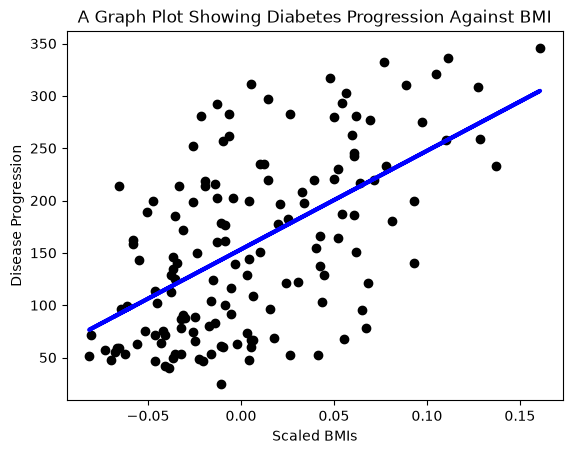

In [8]:
plt.scatter(X_test, y_test,  color='black')
plt.plot(X_test, y_pred, color='blue', linewidth=3)
plt.xlabel('Scaled BMIs')
plt.ylabel('Disease Progression')
plt.title('A Graph Plot Showing Diabetes Progression Against BMI')
plt.show()


## Assignment
查看 Scikit-learn 中的 Linnerud 数据集。这个数据集包含多个目标变量：“它由三项运动（数据）和三项生理指标（目标变量）组成，这些数据是从一家健身俱乐部的二十名中年男性中收集的。”
用你自己的话描述如何创建一个回归模型，以绘制腰围与完成仰卧起坐次数之间的关系。同样，针对该数据集中的其他数据点也进行类似的描述。

## 回答
在这个回归分析任务中，我们使用了 Scikit-learn 内置的 **Linnerud 数据集**。该数据集包含了 20 名中年男性的锻炼数据（特征变量：引体向上、仰卧起坐、跳跃）和生理指标（目标变量：体重、腰围、脉搏）。

**以“仰卧起坐次数”和“腰围”为例，构建回归模型的过程如下：**

首先，我们需要从数据集中提取特定列。我们将“仰卧起坐（Situps）”作为输入特征 \(X\)，将“腰围（Waist）”作为目标变量 \(y\)。由于 Scikit-learn 要求输入的特征矩阵必须是二维的，我们需要使用切片 `X = data[:, 1:2]` 或通过 `reshape(-1, 1)` 来保持二维结构。接着，我们实例化 `LinearRegression()` 模型，使用 `model.fit(X, y)` 让模型学习这两组数据之间的关系。最后，我们可以利用 `model.predict(X)` 计算出预测值，并结合 Matplotlib 在散点图上绘制出一条最佳拟合直线。

**模型的实际用途与泛化：**

这条直线反映了仰卧起坐次数与腰围之间的线性映射关系。如果在图上观察，我们不仅能看出两者可能存在的负相关趋势，更重要的是，对于未来一个未知的新样本（比如一个新的锻炼者），只要知道他做了多少次仰卧起坐，我们就可以将数据代入这条直线，直接预测出他的大致腰围。这就是模型的“泛化”能力。

**针对其他数据点的类似描述：**

同理，我们可以对该数据集中的其他变量进行两两配对回归。例如，将“引体向上（Chins）”作为特征 \(X\)，“体重（Weight）”作为目标 \(y\) 进行建模，以预测不同锻炼水平下的体重趋势；或者将“跳跃次数（Jumps）”作为特征 \(X\)，“脉搏（Pulse）”作为目标 \(y\) 进行建模。这些模型都能通过拟合历史数据点，帮助我们探究运动表现与生理指标之间的潜在关联，并为未见数据提供预测依据。